# Train tiếp ViT / CNN+LSTM với step_penalty (fine-tune từ model đã train)

Nạp hai run đã có trong `runs/` (`vit_dp25_s0`, `lstm_dp25_s0`), train tiếp với `step_penalty > 0`, lưu thành run **mới** (run gốc không bị đụng tới).

- Tên run mới có dạng `{arm}_dp25_sp{SP}_from_pre_s{seed}`, nên nhìn tên là biết đã dùng pretrained và `step_penalty` bao nhiêu.
- `step_penalty` và `death_penalty` cũng được ghi trong log từng update.
- Run mới đã có file `.pt` + `_log.npy` thì bỏ qua, nên chạy lại sau khi bị ngắt vẫn tiếp tục được (run dở sẽ train lại từ model pretrained).
- Đặt `SMOKE = True` để chạy thử nhanh.

In [1]:
from pathlib import Path
import numpy as np
from pacman_rl import PPOConfig, train_ppo, get_device, random_baseline
from pacman_rl.runs import save_run, load_run, list_runs
from pacman_rl.plotting import compare
from pacman_rl.evaluation import ppo_policy, evaluate, watch

device = get_device()
print(device)

cuda


## 1. Tham số

In [2]:
SMOKE = False
STEPS = 16_384 if SMOKE else 1_000_000
SEEDS = [0]
RGB = False                    # phải khớp với model pretrained (False: xám 4 kênh)
RUN_DIR = "runs"
SP = 0.05                      # step_penalty. Reward đã nén log (viên nhỏ ~0.69), 0.1/bước ~ 20 điểm phạt mỗi lượt là rất nặng

# fine-tune: lr thấp hơn lúc train đầu (ViT 1e-4, LSTM 2.5e-4)
ARMS = {
    "vit":  dict(arch="vit",  lr=5e-5),
    "lstm": dict(arch="lstm", lr=1e-4),
}
# run nguồn (pretrained) cho từng nhánh
PRETRAINED = {"vit": "vit_dp25_s0", "lstm": "lstm_dp25_s0"}

def run_name(arm, seed):
    return ("smoke_" if SMOKE else "") + f"{arm}_dp25_sp{SP}_from_pre" + ("_rgb" if RGB else "") + f"_s{seed}"

def make_cfg(seed, **kw):
    return PPOConfig(
        total_steps=STEPS, seed=seed, death_penalty=2.5, step_penalty=SP, rgb_scale=RGB,
        n_envs=4 if SMOKE else 32,
        n_steps=128 if SMOKE else 512,
        n_minibatches=4,
        save_every=200 if SMOKE else 50_000,
        log_every=2 if SMOKE else 50,
        **kw)

missing = [p for p in PRETRAINED.values() if not Path(f"{RUN_DIR}/{p}.pt").exists()]
assert not missing, f"thiếu run pretrained: {missing}"
print([run_name(a, s) for s in SEEDS for a in ARMS], STEPS)

['vit_dp25_sp0.05_from_pre_s0', 'lstm_dp25_sp0.05_from_pre_s0'] 1000000


## 2. Train tiếp
Mỗi nhánh nạp trọng số từ `PRETRAINED[arm]` rồi truyền vào `train_ppo(model=...)`. Lưu ý: optimizer (Adam) được tạo mới và `lr` giảm tuyến tính về 0 trong lần train này.

In [3]:
for seed in SEEDS:
    for arm, kw in ARMS.items():
        name = run_name(arm, seed)
        if Path(f"{RUN_DIR}/{name}.pt").exists() and Path(f"{RUN_DIR}/{name}_log.npy").exists():
            print(f"bỏ qua {name} (đã có)")
            continue
        # load_run trả model ở eval(); LSTM cuDNN không backward được ở eval nên phải .train()
        pre = load_run(RUN_DIR, PRETRAINED[arm], "ppo", device).model.train()
        print(f"=== {name} (pretrained từ {PRETRAINED[arm]}) ===")
        result = train_ppo(cfg=make_cfg(seed, **kw), model=pre, save_path=f"{RUN_DIR}/{name}.pt", device=device)
        save_run(result, RUN_DIR, name, append=False)

bỏ qua vit_dp25_sp0.05_from_pre_s0 (đã có)
=== lstm_dp25_sp0.05_from_pre_s0 (pretrained từ lstm_dp25_s0) ===
PPO: 61 updates x 16384 mẫu = 999,424 bước, 32 env song song
Update 50/61 | step 819,200 | avg score(20) 772 | 3692 lượt | 222 bước/lượt | 0.35 viên NL/lượt | 0.21 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.796 | KL 0.0007 | clipfrac 0.005 | 1186 steps/s
Update 61/61 | step 999,424 | avg score(20) 676 | 829 lượt | 217 bước/lượt | 0.31 viên NL/lượt | 0.17 ma/lượt | phạt chết 2.5 bước 0.050 | entropy 1.770 | KL 0.0008 | clipfrac 0.029 | 1185 steps/s


## 3. Đường học: run gốc so với run fine-tune

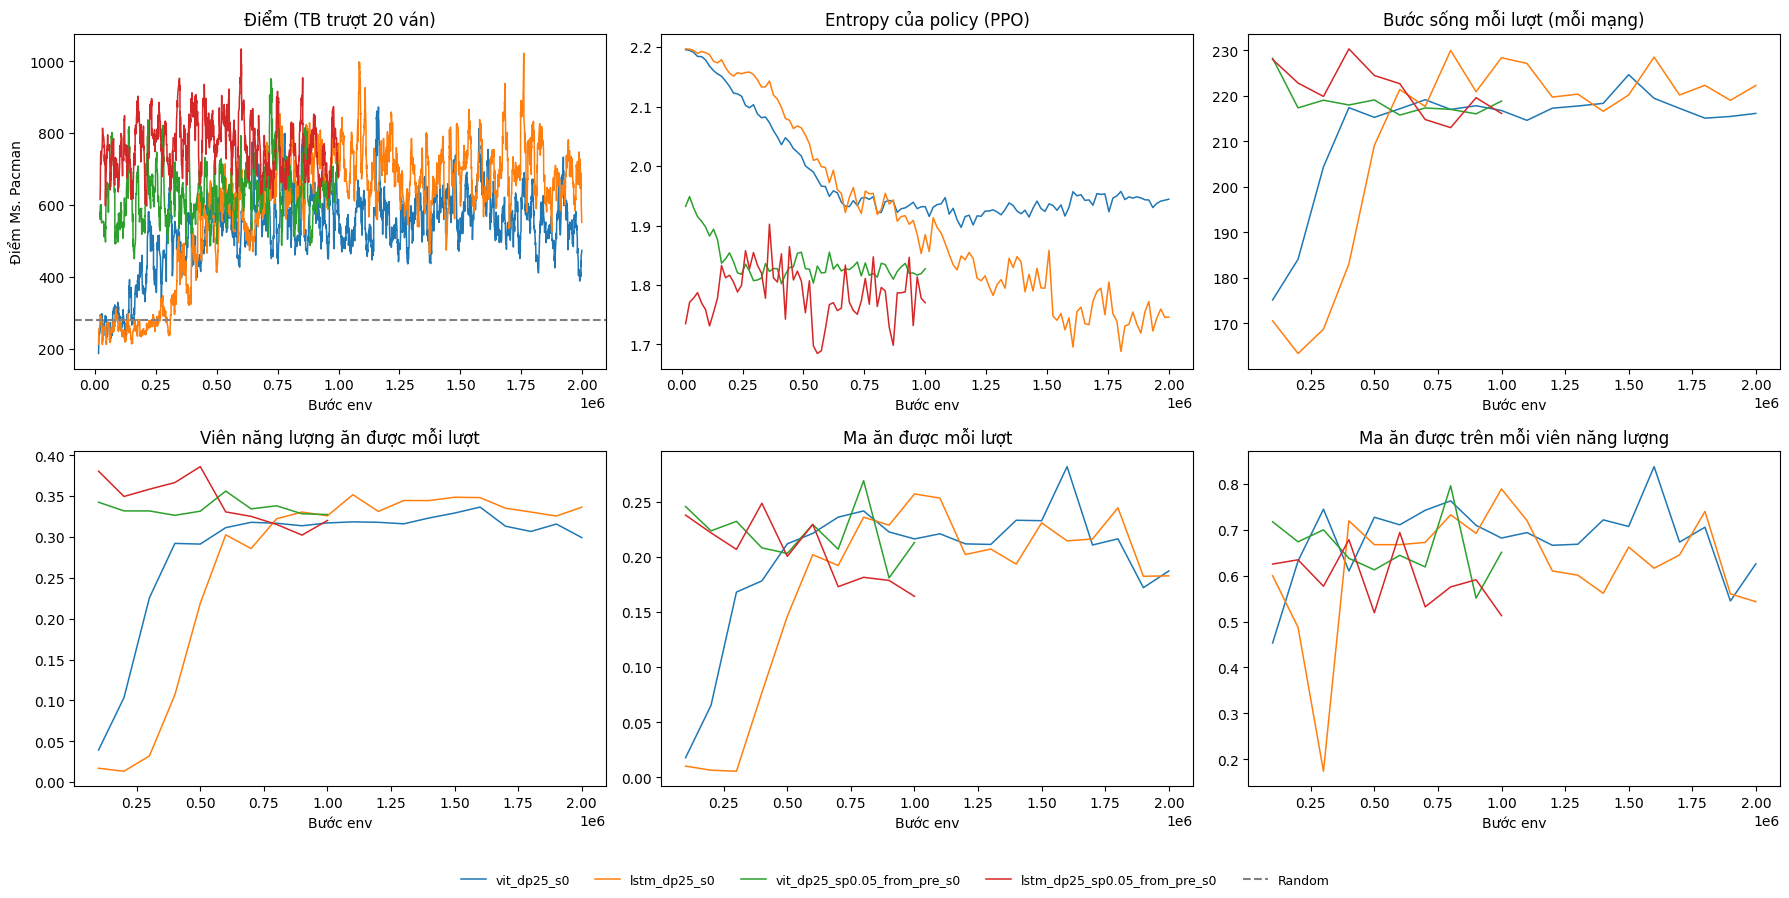

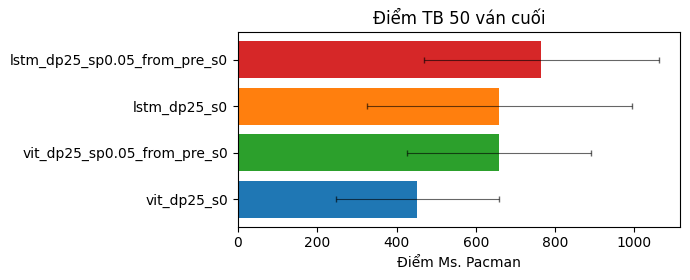

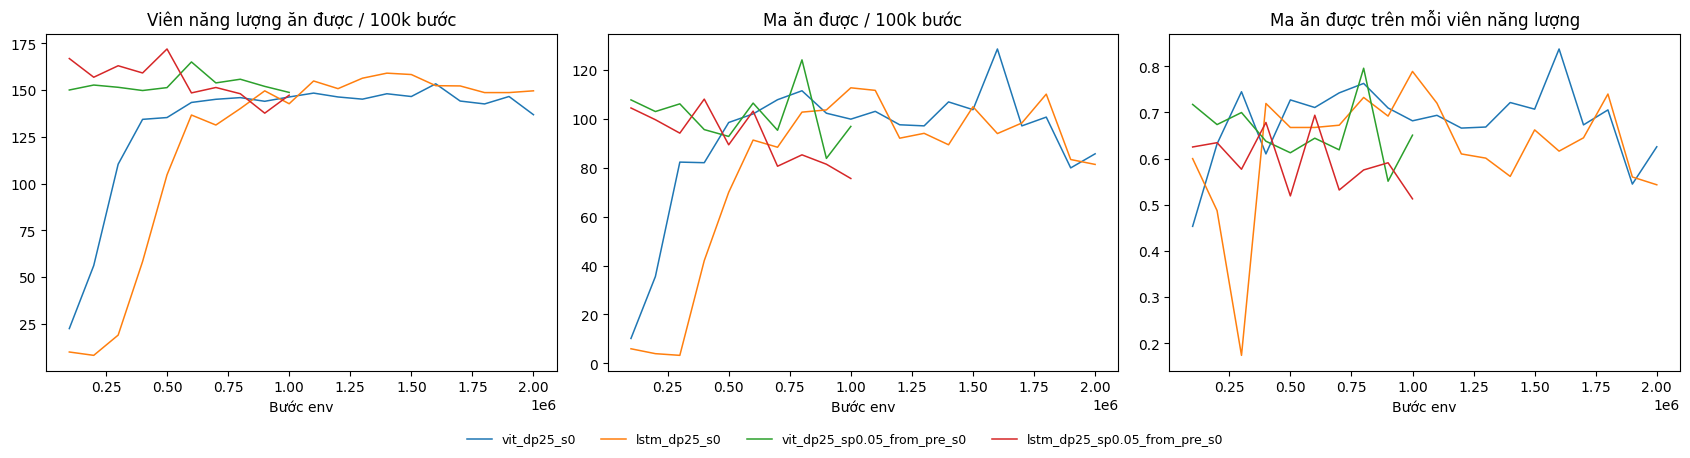

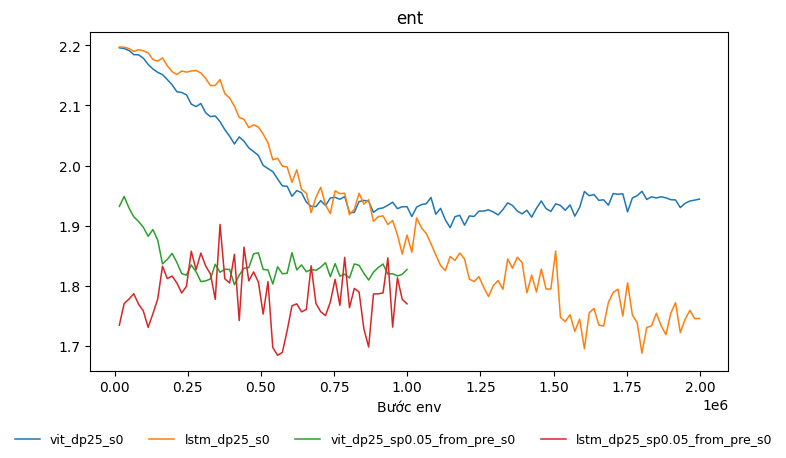

In [4]:
new_names = [run_name(a, s) for s in SEEDS for a in ARMS]
names = [p for p in PRETRAINED.values()] + new_names
runs = compare(names=names, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/finetune_sp{SP}_compare.png")

## 4. Chấm điểm (seed cố định, cùng ván cho mọi model)

In [5]:
N_EVAL = 3 if SMOKE else 20
rows = {}
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:40s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")

c:\Users\LENOVO\miniconda3\envs\rel_pacman\lib\site-packages\torch\nn\modules\transformer.py:720: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:455.)
  return torch._transformer_encoder_layer_fwd(


vit_dp25_s0                              TB     550 | std    226 | max   1270
lstm_dp25_s0                             TB     711 | std    524 | max   2480
vit_dp25_sp0.05_from_pre_s0              TB     748 | std    316 | max   1560
lstm_dp25_sp0.05_from_pre_s0             TB     803 | std    535 | max   2370


## 5. Xem model chơi (cần màn hình)

In [ ]:
WATCH_EPISODES = 1
for n in new_names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    print(f"=== đang chiếu {n} ===")
    watch(ppo_policy(model, device, greedy=False), episodes=WATCH_EPISODES)

=== đang chiếu vit_dp25_sp0.05_from_pre_s0 ===
[play] ván 1: 850 điểm (759 bước)
=== đang chiếu lstm_dp25_sp0.05_from_pre_s0 ===
[play] ván 1: 410 điểm (520 bước)


: 

Ê nha, t thấy điểm trung bình của vit nó thấp hơn nhưng khi test thì lại thấy nó ổn định hơn.